# Intelligent RAG-Based Chatbot using LangChain and LLMs

| Item | Details |
|---|---|
| **Project** | AI Client Project 5 |
| **Program** | DataMites AI |
| **Knowledge Base** | Three arXiv research papers on Retrieval-Augmented Generation (RAG), stored in the `data/` folder |
| **Technology Stack** | LangChain, Hugging Face Sentence Transformers, ChromaDB, Groq LLM, RAGAS, Streamlit |
| **Execution Environment** | Anaconda Jupyter Notebook |
| **RAGAS Judge Model** | Configurable; defaults to `qwen/qwen3.8-27b` when available |

This notebook builds a document-grounded question-answering chatbot. It loads PDF, TXT, and Markdown files from the local `data/` folder, extracts and cleans text, splits it into overlapping chunks, generates embeddings, stores them in ChromaDB, retrieves relevant passages, and uses a Groq-hosted Large Language Model to generate answers based on the retrieved context.

The notebook is self-contained. It creates the required project files and directories, including `rag_core.py`, `app.py`, `data/`, `vectorstore/`, and `results/`, and downloads the three arXiv PDFs automatically if they are not already available. The Streamlit chatbot interface is generated in Section 16. Shared functionality, including hybrid retrieval and answer generation, is implemented in `rag_core.py` in Section 5.

### Contents

- Problem Statement and Project Objectives
- System Architecture
- Project Setup and Execution Guide
1. Install Libraries
2. Environment and Package Versions
3. Import Required Libraries
4. Groq API Key
5. Helper Module (`rag_core.py`)
6. Project Folders and Source Documents
7. Load, Clean and Chunk Documents
8. Data Checks and Corpus Statistics
9. Embeddings and ChromaDB Index
10. Hybrid Retrieval and LLM Answer Generation
11. Abstention Test (Out-of-Scope Questions)
12. RAGAS Evaluation (10 Q&A Pairs)
13. Retrieval Experiment (Mode, Chunk Size and Top-k)
14. Results Summary
15. Command-Line Chat Test
16. Streamlit Chat Interface (`app.py`)
17. Save Vector Store and Result Files
18. Design Choices and Evaluation Notes
19. Test Results and Known Limitations
20. Client Requirement Audit
21. Generate Project README


## Problem Statement and Project Objectives

### Problem Domain: Research Paper Question Answering

Retrieval-Augmented Generation (RAG) is an important approach for improving the accuracy and relevance of Large Language Model responses by retrieving information from external knowledge sources.

However, understanding technical RAG research papers can be time-consuming. Users often need to search multiple documents manually to find specific concepts, methods, architectures and evaluation techniques. General-purpose language models may also generate responses that are not directly supported by the selected research documents.

### Problem Statement

The objective of this project is to develop an intelligent RAG-based chatbot that can answer user questions using information retrieved from three selected arXiv research papers about Retrieval-Augmented Generation.

The system combines semantic vector search and BM25 keyword retrieval to identify relevant document passages. These passages are provided as context to a Groq-hosted Large Language Model, which generates answers grounded in the retrieved information.

The chatbot also provides source filenames and page references to help users verify the generated responses.

### Project Objectives

1. Load and process research papers in PDF, TXT and Markdown formats.
2. Clean and split document content into overlapping text chunks.
3. Generate text embeddings using Hugging Face Sentence Transformers.
4. Store and retrieve document embeddings using ChromaDB.
5. Implement hybrid retrieval using vector similarity and BM25 keyword search.
6. Generate context-grounded answers using a Groq-hosted LLM.
7. Prevent unsupported answers through an out-of-scope abstention mechanism.
8. Evaluate response quality using RAGAS metrics.
9. Provide an interactive chatbot interface using Streamlit.

### Target Users

- Students learning Retrieval-Augmented Generation.
- Researchers exploring RAG techniques.
- Developers interested in document-based question-answering systems.

### Scope and Limitations

The chatbot is designed specifically for the three research papers included in its local knowledge base. It is not a general-purpose web search engine.

PDF extraction may not preserve complex equations, tables or figures accurately. OCR is not implemented for scanned documents. Retrieval performance can vary depending on chunk size, embedding similarity and question wording.

RAGAS scores are LLM-judge estimates and should be interpreted in the context of the ten reference questions used in this project.

### Success Criteria

- Faithfulness score of at least 0.85.
- Answer Relevancy score of at least 0.80.
- Unsupported questions should receive an abstention response.
- Generated answers should include source filenames and page references.


## System Architecture

The proposed system follows a Retrieval-Augmented Generation (RAG) architecture. It combines semantic vector retrieval and BM25 keyword retrieval to identify relevant passages from research papers before generating an answer.

### End-to-End Workflow

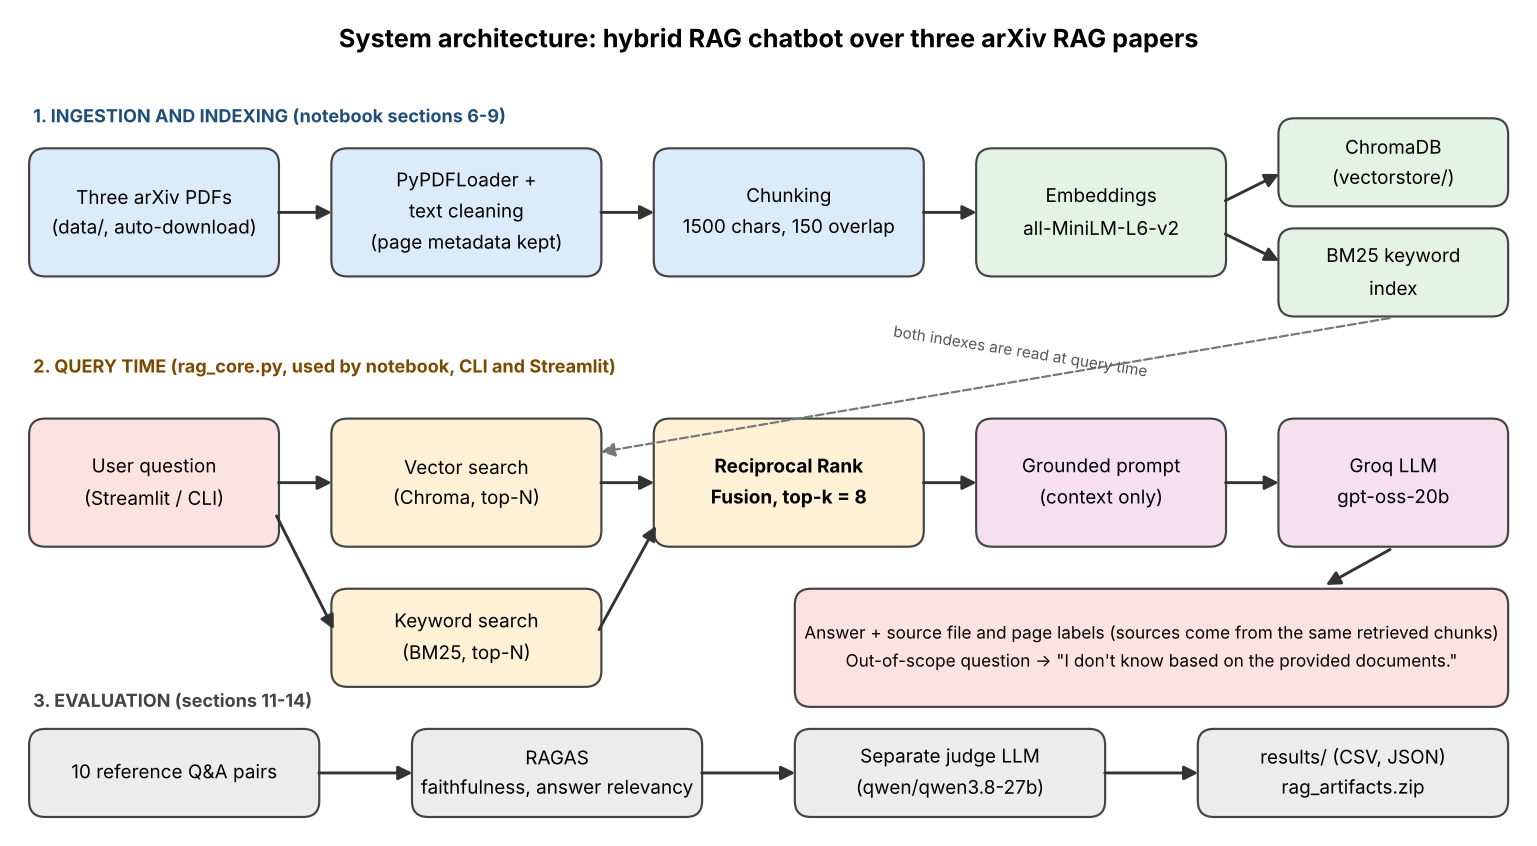

*Figure: ingestion and indexing, hybrid query-time retrieval, grounded generation with citations, and the evaluation workflow.*

### Main Architecture Components

1. **Document Ingestion:** Loads the three arXiv research papers using LangChain PDF loading utilities.
2. **Text Processing:** Cleans extracted text and splits it into overlapping chunks.
3. **Embedding Generation:** Uses a Hugging Face Sentence Transformer model to generate vector representations.
4. **Vector Database:** Stores document embeddings in a persistent ChromaDB collection.
5. **Keyword Retrieval:** Uses BM25 to retrieve passages based on keyword relevance.
6. **Hybrid Retrieval:** Combines vector and keyword results using Reciprocal Rank Fusion (RRF).
7. **Answer Generation:** Sends retrieved passages and the user question to the Groq-hosted LLM using a grounded prompt.
8. **Source Attribution:** Includes source filenames and page references in generated answers.
9. **User Interface:** Supports interaction through a Jupyter CLI and a Streamlit application.
10. **Evaluation:** Uses RAGAS to measure Faithfulness and Answer Relevancy on ten reference question-answer pairs.

### Application Execution

The notebook builds and evaluates the RAG pipeline. Section 16 generates the `app.py` Streamlit application. The application uses the persistent `vectorstore/` directory created during the vector database setup.


## Project Setup and Execution Guide

### Project Overview

This project implements an intelligent Retrieval-Augmented Generation (RAG) chatbot using LangChain and Large Language Models (LLMs).

The chatbot answers user questions using information retrieved from three selected arXiv research papers related to Retrieval-Augmented Generation. It combines semantic vector search and BM25 keyword retrieval to identify relevant document passages and generates context-grounded responses using a Groq-hosted LLM.

The system also provides source filenames and page references to support answer verification.

### Technologies Used

| Component | Technology |
|---|---|
| Programming Language | Python |
| RAG Framework | LangChain |
| Embedding Model | Hugging Face Sentence Transformers |
| Vector Database | ChromaDB |
| Keyword Retrieval | BM25 |
| Hybrid Ranking | Reciprocal Rank Fusion |
| LLM Provider | Groq |
| Evaluation Framework | RAGAS |
| User Interface | Streamlit |

### Project Requirements

- Python environment compatible with the required dependencies.
- Jupyter Notebook or JupyterLab.
- Internet connection for downloading research papers and embedding models.
- Valid Groq API key.

**Test Environment:** The recorded implementation was tested using Python 3.13.9 on Windows 11. Package compatibility may vary across environments.

### Installation and Setup

1. Open the notebook using Jupyter Notebook or JupyterLab.
2. Execute the package installation cell.
3. Run the import and environment verification cells.
4. Enter the Groq API key when prompted. The notebook uses a hidden input prompt to avoid displaying the key.
5. Execute the remaining notebook cells sequentially.

### Dataset Description

The knowledge base consists of three selected arXiv research papers related to Retrieval-Augmented Generation.

The notebook downloads the research papers into the local `data/` directory if they are not already available.

Supported document formats:
- PDF
- TXT
- Markdown

### System Workflow

1. Load research documents.
2. Extract and clean document text.
3. Split text into overlapping chunks.
4. Generate embeddings using the `all-MiniLM-L6-v2` model.
5. Store document embeddings in ChromaDB.
6. Retrieve relevant passages using semantic vector search and BM25 keyword search.
7. Combine retrieval rankings using Reciprocal Rank Fusion (RRF).
8. Generate context-grounded answers using the Groq LLM.
9. Display source filenames and page references.
10. Evaluate answer quality using RAGAS.

### Running the Chatbot

After completing the document indexing and vector database creation:

1. Execute the notebook cell that generates `app.py`.
2. Open Anaconda Prompt or a terminal in the project directory.
3. Run the following command:

```bash
python -m streamlit run app.py
```

4. Open the local URL displayed in the terminal to access the chatbot.

### Evaluation and Results

The project evaluates chatbot performance using the following measures:

- Faithfulness
- Answer Relevancy
- Retrieval Hit Rate
- Out-of-scope Question Handling

**Recorded Execution Results**

| Evaluation Metric | Observed Result |
|---|---:|
| Documents Processed | 61 pages |
| Text Chunks Created | 202 |
| Retrieval Hit Rate | 0.90 |
| Out-of-Scope Abstention | 100% (4/4) |
| QA Generation | 10/10 |
| Faithfulness | 0.883 |
| Answer Relevancy | 0.813 |

The recorded Faithfulness and Answer Relevancy scores meet the project's target thresholds of 0.85 and 0.80, respectively.

These results are based on the recorded notebook execution. Results may vary when the notebook is executed again.

### Troubleshooting

- **Groq API rate limit:** Wait until the applicable quota resets and retry the relevant cell.
- **Missing packages:** Execute the package installation cell again.
- **Embedding download issues:** Check the internet connection.
- **Streamlit launch issues:** Verify that `app.py` has been generated and use `python -m streamlit run app.py`.
- **PDF extraction limitations:** Complex tables, equations, figures and scanned text may not be extracted reliably.

### Security Notes

- Never hardcode API keys in notebook source code.
- Do not share API keys or commit them to public repositories.
- Use secure input methods or environment variables for API configuration.
- Ensure that no actual secret credentials are present before submitting the notebook.

### Generated Project Artifacts

The notebook generates the following project artifacts during execution:

- `rag_core.py` – Core RAG implementation.
- `data/` – Downloaded research documents.
- `vectorstore/` – Persistent ChromaDB vector database.
- `results/` – Evaluation results and related outputs.
- `app.py` – Streamlit chatbot application.
- `rag_artifacts.zip` – Packaged project artifacts.

### Limitations

- The knowledge base is restricted to the three selected research papers.
- OCR for scanned documents is not implemented.
- Complex tables, figures and mathematical equations may not be extracted accurately.
- Retrieval and generation quality depend on document quality, chunking configuration and model behavior.
- RAGAS scores are estimates based on the selected evaluation dataset and judge model.

### Conclusion

This project demonstrates an end-to-end RAG-based chatbot integrating LangChain, Hugging Face embeddings, ChromaDB, BM25 hybrid retrieval, Groq LLMs and RAGAS evaluation.

The system provides document-grounded answers with source references through both a Jupyter command-line interface and a Streamlit application.


## 1. Install Libraries

Installs the packages used by this notebook. Run it once per environment.


In [1]:
%pip install -q langchain-community langchain-text-splitters langchain-chroma langchain-huggingface langchain-groq chromadb sentence-transformers pypdf ragas datasets pandas rank-bm25 streamlit

## 2. Environment and Package Versions

Prints the package versions used in this run. Copy them into `requirements.txt` to pin the environment.


In [1]:
import sys
import platform
import importlib.metadata as metadata

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

packages = [
    "langchain-community", "langchain-text-splitters", "langchain-chroma",
    "langchain-huggingface", "langchain-groq", "chromadb",
    "sentence-transformers", "pypdf", "ragas", "datasets", "rank-bm25", "streamlit"
]
for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")


Python: 3.13.9
Platform: Windows-11-10.0.26300-SP0
langchain-community: 0.4.2
langchain-text-splitters: 1.1.3
langchain-chroma: 1.1.0
langchain-huggingface: 1.2.3
langchain-groq: 1.2.1
chromadb: 1.5.9
sentence-transformers: 6.2.0
pypdf: 6.20.1
ragas: 0.4.4
datasets: 5.1.0
rank-bm25: 0.2.2
streamlit: 1.67.0


## 3. Import Required Libraries

In this section, we import all the necessary Python libraries and modules required to build the RAG-based chatbot.

These libraries are used for:
- Document loading and text extraction
- Text preprocessing and chunking
- Text embeddings and vector database storage
- LLM integration using Groq
- Data processing and evaluation


In [2]:
import os
import re
import json
import hashlib
import shutil
import sys
import getpass
import unicodedata
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

from pypdf import PdfReader
from langchain_community.document_loaders import PyPDFLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
import rank_bm25  # keyword search used by the hybrid retriever

warnings.filterwarnings("ignore")
print("All required libraries imported successfully.")


C:\Users\sarav\AppData\Local\Temp\ipykernel_30156\2322259434.py:17: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader, TextLoader


All required libraries imported successfully.


## 4. Groq API Key

Free key: https://console.groq.com/keys


In [3]:
import os, getpass
os.environ['GROQ_API_KEY'] = getpass.getpass('Paste your Groq API key and press Enter: ').strip()
print('Key set for this session.')

Paste your Groq API key and press Enter:  ········


Key set for this session.


## 5. Helper Module (`rag_core.py`)

This cell writes the shared helper module (hybrid retrieval with reciprocal rank fusion, the grounded prompt, safe answer generation, checkpoint signatures). The notebook and the Streamlit app both import it, so they behave identically.


In [23]:
%%writefile rag_core.py
"""Retrieval and answer helpers shared by the notebook and the Streamlit app.

Why this module exists
----------------------
* Hybrid retrieval: dense vector search finds passages with similar meaning, BM25 keyword search
  finds passages that share the question's exact terms. Scientific text contains many specific
  terms (method names, numbers), so combining both with reciprocal rank fusion is more robust
  than either one alone.
* Reliable answers: a model call that returns an empty string is retried and never stored as a result.
* One prompt and one set of helpers for the notebook and the app, so both behave the same way.
"""
from __future__ import annotations

import hashlib
import json
import re
import time

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from rank_bm25 import BM25Okapi

ABSTAIN_TEXT = "I don't know based on the provided documents."

SYSTEM_PROMPT = (
    "You are a document-grounded assistant. Answer the question using ONLY the retrieved context. "
    "Do not use outside knowledge or invent facts. If the answer is not supported by the context, "
    "reply exactly: " + ABSTAIN_TEXT + " Keep the answer clear and concise. "
    "When useful, cite the source and page label shown in the context.\n\nContext:\n{context}"
)

STOPWORDS = frozenset(
    "the a an of in to and for is are was were be by with on as that this it its from or at "
    "what which how does do did used use between about into their there".split()
)


class EmptyAnswerError(RuntimeError):
    """The language model kept returning an empty answer."""


class ModelRateLimitError(RuntimeError):
    """The model provider rejected a request because its rate/token quota was reached."""


def tokenize(text: str) -> list[str]:
    """Lower-case alphanumeric tokens without stop words (used for BM25)."""
    return [t for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in STOPWORDS]


def page_label(doc: Document) -> str:
    """Human-friendly source label. PyPDFLoader stores zero-based page numbers."""
    source = doc.metadata.get("source", "unknown")
    page = doc.metadata.get("page")
    return f"{source}, p. {int(page) + 1}" if page is not None else source


def doc_key(doc: Document) -> tuple:
    """Identity of a chunk: source, page and a hash of its text."""
    digest = hashlib.md5(doc.page_content.encode("utf-8")).hexdigest()
    return (doc.metadata.get("source", ""), doc.metadata.get("page", ""), digest)


def reciprocal_rank_fusion(rankings: list[list], k: int = 60) -> list[tuple]:
    """Fuse several ranked lists of keys. Higher score = better. Returns [(key, score)]."""
    scores: dict = {}
    for ranking in rankings:
        for rank, key in enumerate(ranking, start=1):
            scores[key] = scores.get(key, 0.0) + 1.0 / (k + rank)
    return sorted(scores.items(), key=lambda item: -item[1])


def docs_from_chroma(vectorstore) -> list[Document]:
    """Rebuild the chunk list from a persisted Chroma collection (used by the Streamlit app)."""
    data = vectorstore.get(include=["documents", "metadatas"])
    return [
        Document(page_content=text, metadata=meta or {})
        for text, meta in zip(data["documents"], data["metadatas"])
    ]


class HybridRetriever:
    """Vector, keyword (BM25) or hybrid retrieval over the same chunk list."""

    MODES = ("hybrid", "vector", "keyword")

    def __init__(self, vectorstore, docs, candidates: int = 20, rrf_k: int = 60):
        self.vectorstore = vectorstore
        self.docs = list(docs)
        self.candidates = candidates
        self.rrf_k = rrf_k
        self._by_key = {doc_key(d): d for d in self.docs}
        self._bm25 = BM25Okapi([tokenize(d.page_content) or [""] for d in self.docs])

    def vector_search(self, query: str, n: int) -> list[Document]:
        return self.vectorstore.similarity_search(query, k=n)

    def keyword_search(self, query: str, n: int) -> list[Document]:
        tokens = tokenize(query)
        if not tokens:
            return []
        scores = self._bm25.get_scores(tokens)
        order = sorted(range(len(scores)), key=lambda i: -scores[i])[:n]
        return [self.docs[i] for i in order if scores[i] > 0]

    def search(self, query: str, k: int = 6, mode: str = "hybrid") -> list[Document]:
        if mode == "vector":
            return self.vector_search(query, k)
        if mode == "keyword":
            return self.keyword_search(query, k)
        if mode != "hybrid":
            raise ValueError(f"Unknown retrieval mode: {mode!r}. Use one of {self.MODES}.")
        vector_docs = self.vector_search(query, self.candidates)
        keyword_docs = self.keyword_search(query, self.candidates)
        fused = reciprocal_rank_fusion(
            [[doc_key(d) for d in vector_docs], [doc_key(d) for d in keyword_docs]], k=self.rrf_k
        )
        lookup = {doc_key(d): d for d in vector_docs + keyword_docs}
        return [self._by_key.get(key) or lookup[key] for key, _ in fused[:k]]


def build_prompt() -> ChatPromptTemplate:
    return ChatPromptTemplate.from_messages([("system", SYSTEM_PROMPT), ("human", "{question}")])


def format_context(docs: list[Document]) -> str:
    return "\n\n---\n\n".join(f"[Source: {page_label(d)}]\n{d.page_content}" for d in docs)


def _as_text(content) -> str:
    if isinstance(content, str):
        return content.strip()
    if isinstance(content, list):  # some chat models return a list of content parts
        parts = [p.get("text", "") if isinstance(p, dict) else str(p) for p in content]
        return "".join(parts).strip()
    return str(content or "").strip()


def generate_answer(llm, prompt, question: str, docs: list[Document],
                    retries: int = 3, wait_seconds: float = 3.0) -> str:
    """Ask the LLM for an answer. Empty replies may be retried; provider 429s fail fast."""
    messages = prompt.format_messages(context=format_context(docs), question=question)
    for attempt in range(1, retries + 1):
        try:
            response = llm.invoke(messages)
        except Exception as exc:
            # Do not retry a daily-token/rate-limit error: another immediate call cannot help.
            message = str(exc).lower()
            status = getattr(exc, "status_code", None)
            code = getattr(exc, "code", None)
            if status == 429 or "rate_limit_exceeded" in message or "tokens per day" in message:
                raise ModelRateLimitError(
                    "The LLM provider quota is exhausted or rate-limited. "
                    "Wait for the reset or switch to another model enabled for your API key."
                ) from exc
            raise

        text = _as_text(response.content)
        if text:
            return text
        if attempt < retries:
            time.sleep(wait_seconds)
    raise EmptyAnswerError(f"The model returned an empty answer {retries} times for: {question[:80]}")


def stable_signature(payload: dict) -> str:
    """Short hash that changes whenever the configuration or the questions change."""
    return hashlib.sha256(json.dumps(payload, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()[:16]


Overwriting rag_core.py


## 6. Project Folders and Source Documents

The three project PDFs live in the `data/` folder next to this notebook. If they are missing, the next cell downloads them from arXiv. This section sets local paths for Anaconda Jupyter; it does not use Google Colab upload tools.


In [24]:
# Download the three arXiv papers into data/ if they are not there yet.
import urllib.request
from pathlib import Path

PAPERS = {
    "2005.11401v4.pdf": "https://arxiv.org/pdf/2005.11401v4",  # RAG, Lewis et al., 2020
    "2312.10997v5.pdf": "https://arxiv.org/pdf/2312.10997v5",  # RAG for LLMs: A Survey
    "2405.07437v2.pdf": "https://arxiv.org/pdf/2405.07437v2",  # Evaluation of RAG: A Survey
}
Path("data").mkdir(exist_ok=True)
for name, url in PAPERS.items():
    target = Path("data") / name
    if target.exists() and target.stat().st_size > 100_000:
        continue
    try:
        urllib.request.urlretrieve(url, str(target))
        print("Downloaded", name)
    except Exception as exc:
        print(f"Could not download {name} ({type(exc).__name__}). Copy it into the data/ folder manually.")
print("PDFs in data/:", sorted(p.name for p in Path("data").glob("*.pdf")))


PDFs in data/: ['2005.11401v4.pdf', '2312.10997v5.pdf', '2405.07437v2.pdf']


In [4]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
VECTOR_DIR = PROJECT_DIR / "vectorstore"
RESULTS_DIR = PROJECT_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

supported_files = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".pdf", ".txt", ".md"}
)

print("Project directory:", PROJECT_DIR.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Vector store directory:", VECTOR_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())
print("Supported documents found:", len(supported_files))
for file in supported_files:
    print(" -", file.name)

if not supported_files:
    raise FileNotFoundError(
        "No PDF/TXT/MD files found. Copy the three project PDFs into the 'data' folder "
        "next to this notebook, then rerun this cell."
    )

# The notebook imports helper functions from rag_core.py, which must sit next to it.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
if not (PROJECT_DIR / "rag_core.py").exists():
    raise FileNotFoundError("rag_core.py was not found next to this notebook. Keep all project files in one folder.")


Project directory: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients
Data directory: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\data
Vector store directory: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\vectorstore
Results directory: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\results
Supported documents found: 3
 - 2005.11401v4.pdf
 - 2312.10997v5.pdf
 - 2405.07437v2.pdf


## 7. Load, Clean and Chunk Documents

Loads the documents from `data/`, cleans the extracted text and splits it into overlapping chunks (1,500 characters with a 150-character overlap). The file name and page number stay attached to every chunk as metadata.


In [5]:
import re, unicodedata
from collections import Counter
from pathlib import Path
from langchain_community.document_loaders import PyPDFLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

def clean_pages(pages):
    """Remove lines that repeat on most pages (headers/footers/page numbers)."""
    if len(pages) < 10:
        return pages
    key = lambda l: re.sub(r'\d+', '', l).strip()
    counts = Counter()
    for d in pages:
        counts.update({key(l) for l in d.page_content.splitlines() if key(l)})
    common = {k for k, c in counts.items() if c / len(pages) > 0.4}
    for d in pages:
        kept = [l for l in d.page_content.splitlines() if key(l) and key(l) not in common]
        d.page_content = re.sub(r'\s+', ' ', ' '.join(kept)).strip()
    return pages

docs = []
for path in sorted(DATA_DIR.rglob('*')):
    ext = path.suffix.lower()
    if ext == '.pdf':
        pages = PyPDFLoader(str(path)).load()
    elif ext in ('.txt', '.md'):
        pages = TextLoader(str(path), encoding='utf-8').load()
    else:
        continue
    for d in pages:
        d.metadata['source'] = path.name
        # arXiv PDFs use ligature glyphs (e.g. 'fi', 'fl'); NFKC turns them into plain letters for search.
        d.page_content = unicodedata.normalize('NFKC', d.page_content)
    docs.extend(clean_pages(pages))

pages_loaded = len(docs)
docs = [d for d in docs if len(d.page_content) > 40]
chunks = RecursiveCharacterTextSplitter(chunk_size=1500, chunk_overlap=150).split_documents(docs)
print(len(docs), 'pages ->', len(chunks), 'chunks')
print('\nSample chunk:\n', chunks[len(chunks)//2].page_content[:300])

61 pages -> 202 chunks

Sample chunk:
 models across diverse application scenarios.This chapter will mainly introduce the main downstream tasks of RAG, datasets, and how to evaluate RAG systems. A. Downstream Task The core task of RAG remains Question Answering (QA), including traditional single-hop/multi-hop QA, multiple- choice, domain


## 8. Data Checks and Corpus Statistics

Fails early if nothing was extracted, and reports how many pages and chunks each document produced. The chunk manifest is saved later (Section 17) so the exact chunks behind every answer can be traced.


In [6]:
import os
import pandas as pd

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
assert docs and chunks, 'No text was extracted. Check that the uploaded PDFs contain selectable text (not scans).'
assert all(c.metadata.get('source') for c in chunks), 'A chunk has no source metadata.'

manifest = pd.DataFrame({
    'source': [c.metadata.get('source') for c in chunks],
    'page': [int(c.metadata['page']) + 1 if c.metadata.get('page') is not None else None for c in chunks],
    'n_chars': [len(c.page_content) for c in chunks],
    'preview': [c.page_content[:80] for c in chunks],
})
manifest.insert(0, 'chunk_id', range(len(manifest)))

per_doc = manifest.groupby('source').agg(chunks=('chunk_id', 'count'), pages=('page', 'nunique'), mean_chars=('n_chars', 'mean'))
print('Pages loaded:', pages_loaded, '| pages kept (more than 40 characters):', len(docs), '| chunks:', len(chunks))
display(per_doc.round(0))
print('Chunk length in characters: min', manifest.n_chars.min(), '| median', int(manifest.n_chars.median()), '| max', manifest.n_chars.max())
print('Duplicate chunks:', len(chunks) - len({c.page_content for c in chunks}))


Pages loaded: 61 | pages kept (more than 40 characters): 61 | chunks: 202


,chunks,pages,mean_chars
source,,,
2005.11401v4.pdf,57,19,1307.0
2312.10997v5.pdf,89,21,1345.0
2405.07437v2.pdf,56,21,1236.0


Chunk length in characters: min 213 | median 1494 | max 1500
Duplicate chunks: 0


## 9. Embeddings and ChromaDB Index

Embeds every chunk with `all-MiniLM-L6-v2` and stores the vectors in a persistent ChromaDB collection in `vectorstore/`. An existing index is reused when the corpus fingerprint has not changed.


In [7]:
import hashlib, json, shutil
from pathlib import Path
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

MANIFEST = VECTOR_DIR / 'corpus_manifest.json'
COLLECTION = 'knowledge_base'

# Fingerprint both content and source metadata so changed uploads trigger re-indexing.
corpus_fingerprint = hashlib.sha256(
    '\n'.join(f"{d.metadata.get('source','')}|{d.metadata.get('page','')}|{d.page_content}" for d in chunks).encode('utf-8')
).hexdigest()

embeddings = HuggingFaceEmbeddings(
    model_name='sentence-transformers/all-MiniLM-L6-v2',
    encode_kwargs={'normalize_embeddings': True}
)

if VECTOR_DIR.exists() and MANIFEST.exists():
    saved = json.loads(MANIFEST.read_text())
else:
    saved = {}

if saved.get('fingerprint') == corpus_fingerprint:
    vectorstore = Chroma(
        collection_name=COLLECTION, embedding_function=embeddings,
        persist_directory=str(VECTOR_DIR)
    )
    print('Reused existing ChromaDB index.')
else:
    shutil.rmtree(VECTOR_DIR, ignore_errors=True)
    VECTOR_DIR.mkdir(parents=True, exist_ok=True)
    vectorstore = Chroma.from_documents(
        chunks, embedding=embeddings, collection_name=COLLECTION,
        persist_directory=str(VECTOR_DIR)
    )
    MANIFEST.write_text(json.dumps({'fingerprint': corpus_fingerprint, 'chunks': len(chunks)}, indent=2))
    print('Built a new ChromaDB index.')

print('Indexed', len(chunks), 'chunks in ChromaDB.')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Built a new ChromaDB index.
Indexed 202 chunks in ChromaDB.


## 10. Hybrid Retrieval and LLM Answer Generation

Retrieval combines two searches over the same chunks: **vector search** (meaning) and **BM25 keyword search** (exact terms such as method names). Their rankings are merged with reciprocal rank fusion. Section 13 measures whether this beats either search alone. `RETRIEVAL_MODE` can be set to `"vector"` or `"keyword"` to compare.

Two models are configured: `ANSWER_MODEL` for answers and `JUDGE_MODEL` for RAGAS. Groq free-plan limits are counted per model, so using two models spreads the daily token budget. If the judge model is not available to your key, the notebook falls back to the answer model and says so.


In [8]:
from groq import Groq
from rag_core import (
    ABSTAIN_TEXT, EmptyAnswerError, ModelRateLimitError, HybridRetriever, build_prompt, generate_answer, page_label, stable_signature,
)

# Answer generation and RAGAS judging use separate model budgets when possible.
ANSWER_MODEL = os.getenv("ANSWER_MODEL", "openai/gpt-oss-20b")
JUDGE_MODEL = os.getenv("JUDGE_MODEL", "qwen/qwen3.8-27b")
RETRIEVAL_MODE = "hybrid"   # "hybrid" (vector + BM25 keyword), "vector" or "keyword"
TOP_K = 8

try:
    available_models = {m.id for m in Groq(api_key=os.environ["GROQ_API_KEY"]).models.list().data}
except Exception as exc:
    available_models = set()
    print(f"Could not list Groq models ({type(exc).__name__}); configured model names will be tried.")

if available_models:
    if ANSWER_MODEL not in available_models:
        raise RuntimeError(
            f"Answer model {ANSWER_MODEL!r} is not available to this API key. "
            f"Available model IDs: {sorted(available_models)}"
        )
    if JUDGE_MODEL not in available_models:
        alternatives = ["qwen/qwen3.8-27b", "openai/gpt-oss-120b", "openai/gpt-oss-20b"]
        replacement = next((m for m in alternatives if m in available_models and m != ANSWER_MODEL), None)
        if replacement:
            print(f"Configured judge model is unavailable; using available model {replacement}.")
            JUDGE_MODEL = replacement
        else:
            print("No separate judge model is enabled for this key; using the answer model. "
                  "The two tasks will share its quota.")
            JUDGE_MODEL = ANSWER_MODEL

print("Answer model:", ANSWER_MODEL, "| Judge model:", JUDGE_MODEL,
      "| Retrieval:", RETRIEVAL_MODE, "| top-k:", TOP_K)

retriever = HybridRetriever(vectorstore, chunks)
llm = ChatGroq(model=ANSWER_MODEL, temperature=0)
prompt = build_prompt()

def answer(question, k=TOP_K, mode=None):
    found = retriever.search(question, k=k, mode=mode or RETRIEVAL_MODE)
    if not found:
        return {
            'question': question, 'answer': ABSTAIN_TEXT,
            'contexts': [], 'sources': [],
        }
    text = generate_answer(llm, prompt, question, found)
    return {
        'question': question, 'answer': text,
        'contexts': [d.page_content for d in found],
        'sources': sorted({page_label(d) for d in found}),
    }

for q in ['What is retrieval-augmented generation?', 'Who won the 2011 cricket world cup?']:
    try:
        out = answer(q)
    except ModelRateLimitError as exc:
        print("\\nLLM quota/rate limit reached:", exc)
        print("The notebook is still usable. Wait for the provider reset or configure another enabled answer model.")
        print("Stopping this demo now so the remaining question does not trigger another failed API request.")
        break
    print('Q:', q)
    print('A:', out['answer'])
    print('Sources:', out['sources'], '\\n')


Answer model: openai/gpt-oss-20b | Judge model: qwen/qwen3.8-27b | Retrieval: hybrid | top-k: 8
Q: What is retrieval-augmented generation?
A: Retrieval‑augmented generation (RAG) is a method that combines a large language model’s internal knowledge with external information retrieved from a database or knowledge base. By fetching relevant documents or facts before or during generation, RAG improves the accuracy and factual grounding of the model’s output, reduces hallucinations, and allows the system to stay up‑to‑date with new information【2405.07437v2.pdf, p. 1】【2312.10997v5.pdf, p. 1】.
Sources: ['2312.10997v5.pdf, p. 1', '2312.10997v5.pdf, p. 11', '2312.10997v5.pdf, p. 17', '2312.10997v5.pdf, p. 18', '2312.10997v5.pdf, p. 20', '2405.07437v2.pdf, p. 1'] \n
Q: Who won the 2011 cricket world cup?
A: I don't know based on the provided documents.
Sources: ['2005.11401v4.pdf, p. 5', '2005.11401v4.pdf, p. 7', '2005.11401v4.pdf, p. 8', '2312.10997v5.pdf, p. 19', '2405.07437v2.pdf, p. 17', '2

## 11. Abstention Test (Out-of-Scope Questions)

The chatbot must answer with the abstention sentence instead of inventing an answer. Four unrelated questions are tested and the abstention rate is reported.


In [10]:
# Test questions that are outside the supplied research-paper knowledge base.
# If the LLM quota is reached, mark the remaining check as skipped rather than counting it as an abstention.

from rag_core import ModelRateLimitError

OUT_OF_SCOPE = [
    "Who won the 2011 cricket world cup?",
    "What is the capital of Australia?",
    "How do I bake a chocolate cake?",
    "What is the current price of Bitcoin?",
]
ABSTAIN = "i don't know based on the provided documents"

def abstained(text):
    return ABSTAIN in text.lower().replace("\u2019", "'")

abst_rows = []
for q in OUT_OF_SCOPE:
    try:
        text = answer(q)["answer"]
    except ModelRateLimitError as exc:
        print("Groq quota/rate limit reached. Stopping remaining out-of-scope tests:", exc)
        abst_rows.append({
            "question": q,
            "abstained": np.nan,
            "answer": "Skipped - Groq rate limit reached."
        })
        break
    except EmptyAnswerError:
        text = "(empty answer from the model)"

    abst_rows.append({
        "question": q,
        "abstained": abstained(text),
        "answer": text[:120]
    })
    print("Q:", q)
    print("A:", text)
    print("-" * 60)

abst_df = pd.DataFrame(abst_rows, columns=["question", "abstained", "answer"])
abst_df["abstained"] = pd.to_numeric(abst_df["abstained"], errors="coerce")
display(abst_df)

tested = int(abst_df["abstained"].notna().sum())
if tested:
    rate = float(abst_df["abstained"].mean())
    print(f"Abstention rate: {rate:.0%} ({int(abst_df['abstained'].sum())} of {tested} tested)")
else:
    print("Abstention rate not available: no out-of-scope questions were completed.")
abst_df.to_csv(str(RESULTS_DIR / "abstention_test.csv"), index=False)


Q: Who won the 2011 cricket world cup?
A: I don't know based on the provided documents.
------------------------------------------------------------
Q: What is the capital of Australia?
A: I don't know based on the provided documents.
------------------------------------------------------------
Q: How do I bake a chocolate cake?
A: I don't know based on the provided documents.
------------------------------------------------------------
Q: What is the current price of Bitcoin?
A: I don't know based on the provided documents.
------------------------------------------------------------


,question,abstained,answer
0,Who won the 2011 cricket world cup?,True,I don't know based on the provided documents.
1,What is the capital of Australia?,True,I don't know based on the provided documents.
2,How do I bake a chocolate cake?,True,I don't know based on the provided documents.
3,What is the current price of Bitcoin?,True,I don't know based on the provided documents.


Abstention rate: 100% (4 of 4 tested)


## 12. RAGAS Evaluation (10 Q&A Pairs)

These pairs are written for the three arXiv papers in `data/`: the original RAG paper (Lewis et al., 2020), *Retrieval-Augmented Generation for Large Language Models: A Survey* and *Evaluation of Retrieval-Augmented Generation: A Survey*. For other documents, replace the questions and ground truths.


In [11]:
QA_PAIRS = [
    {'question': 'What is the difference between RAG-Sequence and RAG-Token?',
     'ground_truth': 'RAG-Sequence uses the same retrieved document to generate the complete output sequence, while RAG-Token can draw a different retrieved document for each target token.'},
    {'question': 'Which retriever and which generator does the original RAG model use?',
     'ground_truth': 'The retriever is DPR (Dense Passage Retriever), a bi-encoder built on BERT-base, and the generator is the pre-trained seq2seq model BART.'},
    {'question': 'How was the Wikipedia knowledge index built in the original RAG paper?',
     'ground_truth': 'They used the December 2018 Wikipedia dump, split each article into disjoint 100-word chunks to get 21M documents, embedded them with the document encoder, and built a single MIPS index using FAISS with a Hierarchical Navigable Small World approximation.'},
    {'question': 'What is index hot-swapping in RAG?',
     'ground_truth': 'Index hot-swapping means the model knowledge can be updated at test time by replacing the non-parametric memory index, whereas parametric-only models such as T5 or BART need further training to update their behavior.'},
    {'question': 'What are the three paradigms of RAG described in the RAG survey for large language models?',
     'ground_truth': 'The three paradigms are Naive RAG, Advanced RAG and Modular RAG.'},
    {'question': 'What are the steps of the Naive RAG process?',
     'ground_truth': 'Naive RAG follows a Retrieve-Read framework of indexing, retrieval and generation: documents are cleaned, split into chunks, embedded and stored in a vector database; the query is encoded with the same model to retrieve the top K most similar chunks; and the LLM generates the answer from the query and the retrieved chunks.'},
    {'question': 'How does Advanced RAG improve on Naive RAG?',
     'ground_truth': 'Advanced RAG improves retrieval quality with pre-retrieval and post-retrieval strategies, and refines indexing using a sliding window approach, fine-grained segmentation and metadata.'},
    {'question': 'What is the "lost in the middle" problem?',
     'ground_truth': 'When the context is too long, the LLM tends to focus only on the beginning and the end of the text and forgets the middle portion, so retrieved content usually needs further processing such as reranking.'},
    {'question': 'What four abilities are used to evaluate RAG models?',
     'ground_truth': 'The four abilities are noise robustness, negative rejection, information integration and counterfactual robustness.'},
    {'question': 'What is Auepora?',
     'ground_truth': 'Auepora is A Unified Evaluation Process of RAG, proposed in the evaluation survey to give a comprehensive overview of RAG evaluation and benchmarks by comparing retrieval and generation metrics such as relevance, accuracy and faithfulness.'},
]


In [13]:
# Generate the 10 answer/reference records used by RAGAS.
# Resumable: every finished answer is saved. The checkpoint is reused ONLY when the questions, models,
# retrieval settings and documents are unchanged, so stale answers can never be reused by mistake.
# An empty model answer is retried and is never saved as a result.

import json
import time
from groq import RateLimitError
from rag_core import ModelRateLimitError

QA_CHECKPOINT = RESULTS_DIR / "qa_generation_checkpoint.json"
QA_SIGNATURE = stable_signature({
    "questions": [qa["question"] for qa in QA_PAIRS],
    "ground_truths": [qa["ground_truth"] for qa in QA_PAIRS],
    "answer_model": ANSWER_MODEL,
    "retrieval_mode": RETRIEVAL_MODE,
    "top_k": TOP_K,
    "corpus": corpus_fingerprint,
})

def load_qa_checkpoint():
    if not QA_CHECKPOINT.exists():
        return []
    try:
        saved = json.loads(QA_CHECKPOINT.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError):
        print("Could not read the QA checkpoint; starting fresh.")
        return []
    if not isinstance(saved, dict) or saved.get("signature") != QA_SIGNATURE:
        print("The QA checkpoint belongs to an older configuration (different questions, model, "
              "retrieval settings or documents). Ignoring it and starting fresh.")
        return []
    restored = []
    for i, record in enumerate(saved.get("rows", [])):
        if (i >= len(QA_PAIRS) or record.get("user_input") != QA_PAIRS[i]["question"]
                or not str(record.get("response", "")).strip()):
            break
        restored.append(record)
    return restored

def save_qa_checkpoint():
    QA_CHECKPOINT.write_text(
        json.dumps({"signature": QA_SIGNATURE, "rows": rows}, ensure_ascii=False, indent=2), encoding="utf-8"
    )

rows = load_qa_checkpoint()
if rows:
    print(f"Restored {len(rows)} valid QA records from the checkpoint.")
print(f"Completed QA records: {len(rows)} / {len(QA_PAIRS)}")

for i in range(len(rows), len(QA_PAIRS)):
    qa = QA_PAIRS[i]
    print(f"\n[{i + 1}/{len(QA_PAIRS)}] {qa['question']}")
    completed = False
    for attempt in range(1, 6):
        try:
            output = answer(qa["question"])
            rows.append({
                "user_input": qa["question"],
                "response": output["answer"],
                "retrieved_contexts": output["contexts"],
                "reference": qa["ground_truth"],
            })
            save_qa_checkpoint()
            print("Saved successfully.")
            completed = True
            time.sleep(15)  # leave room under the Groq tokens-per-minute limit
            break
        except (RateLimitError, ModelRateLimitError) as exc:
            if isinstance(exc, ModelRateLimitError):
                print(f"Groq daily quota/provider limit reached: {exc}")
                print("Stopping now; completed QA records are preserved in the checkpoint.")
                break
            wait_seconds = min(60, 15 * attempt)
            print(f"Groq rate limit (attempt {attempt}/5): {exc}. Waiting {wait_seconds}s.")
            time.sleep(wait_seconds)
        except EmptyAnswerError as exc:
            print(f"Empty answer from the model, nothing saved: {exc}")
            break
        except Exception as exc:
            print(f"Question failed: {type(exc).__name__}: {exc}")
            break

    if not completed:
        print("Stopped safely. Re-run this cell later to continue from the saved checkpoint.")
        break

print(f"\nFinal QA count: {len(rows)} / {len(QA_PAIRS)}")
assert len(rows) <= len(QA_PAIRS), "Unexpected number of QA records."

Restored 10 valid QA records from the checkpoint.
Completed QA records: 10 / 10

Final QA count: 10 / 10


## 13. Retrieval Experiment (Mode, Chunk Size and Top-k)

Does the right passage reach the LLM? This check needs no LLM calls. For each of the 10 questions it looks for a key phrase from the correct passage inside the retrieved chunks and reports the **hit rate** for vector, keyword and hybrid retrieval, three chunk sizes and several values of k. It is a lexical proxy for retrieval quality, not a replacement for RAGAS.

**Selection rule (fixed before looking at the results):** choose the setting with the highest hit rate; ties go to the smaller k, then the smaller chunk size, then the configured retrieval mode. The cell prints the best setting and compares it with the default in use (hybrid, chunk=1500, k=8), so the default is either confirmed or consciously changed.


In [14]:
import re, time
import pandas as pd
from langchain_chroma import Chroma
from langchain_text_splitters import RecursiveCharacterTextSplitter
from rag_core import HybridRetriever

# One phrase per question that must appear in the retrieved text if the right passage was found.
KEY_PHRASES = [
    'same retrieved document to generate the complete sequence', 'bi-encoder architecture', '100-word chunks',
    'index hot-swapping', 'the advanced rag, and the modular rag', 'retrieve-read',
    'sliding window approach', 'lost in the middle',
    'information integration, and counterfactual robustness', 'auepora',
]
assert len(KEY_PHRASES) == len(QA_PAIRS), 'Keep one key phrase per question.'
norm = lambda t: re.sub(r'\s+', ' ', t.lower())

MODES = ('vector', 'keyword', 'hybrid')
KS = (2, 4, 6, 8)

experiment_rows = {}
detail = {}
for size in (500, 1000, 1500):
    exp_chunks = RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=size // 10).split_documents(docs)
    store = Chroma.from_documents(exp_chunks, embedding=embeddings,
                                  collection_name=f'exp_{size}_{int(time.time())}')  # in-memory, temporary
    exp_retriever = HybridRetriever(store, exp_chunks)
    for mode in MODES:
        label = f'{mode} | chunk={size} ({len(exp_chunks)} chunks)'
        experiment_rows[label] = {}
        for k in KS:
            flags = [
                any(phrase in norm(d.page_content) for d in exp_retriever.search(qa['question'], k=k, mode=mode))
                for qa, phrase in zip(QA_PAIRS, KEY_PHRASES)
            ]
            experiment_rows[label][f'k={k}'] = sum(flags) / len(flags)
            detail[(mode, size, k)] = flags
    store.delete_collection()

table = pd.DataFrame(experiment_rows).T
print('Retrieval hit rate (share of the 10 questions whose key phrase was retrieved):')
display(table.round(2))

default_row = next(r for r in table.index if r.startswith(f'{RETRIEVAL_MODE} | chunk=1500'))
missed = [QA_PAIRS[i]['question'] for i, ok in enumerate(detail[(RETRIEVAL_MODE, 1500, TOP_K)]) if not ok]
print(f'\nMissed at the default setting ({RETRIEVAL_MODE}, chunk=1500, k={TOP_K}):', missed if missed else 'none')

# Selection rule (fixed before looking at the results): highest hit rate; ties -> smaller k,
# then smaller chunk size, then the configured retrieval mode.
best = max(
    (table.loc[r, c], -int(c[2:]), -int(r.split('chunk=')[1].split()[0]), r.startswith(RETRIEVAL_MODE), r, c)
    for r in table.index for c in table.columns
)
print(f"\nBest setting by the rule: {best[4]}, {best[5]} (hit rate {best[0]:.2f})")
print(f"Default setting in use: {default_row}, k={TOP_K} (hit rate {table.loc[default_row, f'k={TOP_K}']:.2f})")
table.to_csv(str(RESULTS_DIR / 'retrieval_experiment.csv'))
pd.DataFrame({
    'question': [qa['question'] for qa in QA_PAIRS], 'key_phrase': KEY_PHRASES,
    **{f'{mode}_chunk1500_k{TOP_K}': detail[(mode, 1500, TOP_K)] for mode in MODES},
}).to_csv(str(RESULTS_DIR / 'retrieval_per_question.csv'), index=False)

Retrieval hit rate (share of the 10 questions whose key phrase was retrieved):


,k=2,k=4,k=6,k=8
vector | chunk=500 (569 chunks),0.3,0.3,0.3,0.3
keyword | chunk=500 (569 chunks),0.4,0.4,0.5,0.5
hybrid | chunk=500 (569 chunks),0.3,0.4,0.5,0.5
vector | chunk=1000 (293 chunks),0.2,0.3,0.3,0.3
keyword | chunk=1000 (293 chunks),0.6,0.6,0.7,0.7
hybrid | chunk=1000 (293 chunks),0.4,0.4,0.4,0.5
vector | chunk=1500 (202 chunks),0.1,0.2,0.3,0.4
keyword | chunk=1500 (202 chunks),0.6,0.9,0.9,0.9
hybrid | chunk=1500 (202 chunks),0.4,0.6,0.8,0.9



Missed at the default setting (hybrid, chunk=1500, k=8): ['What four abilities are used to evaluate RAG models?']

Best setting by the rule: keyword | chunk=1500 (202 chunks), k=4 (hit rate 0.90)
Default setting in use: hybrid | chunk=1500 (202 chunks), k=8 (hit rate 0.90)


### Best Retrieval Setting and Chatbot Default

The retrieval experiment showed that **Keyword retrieval with k=4** achieved a hit rate of **0.90**, making it one of the best-performing configurations. **Hybrid retrieval with k=8** also achieved the same hit rate of **0.90**.

Although Keyword retrieval with k=4 performed well in the experiment, Hybrid retrieval with k=8 was selected as the chatbot's default setting because it combines keyword-based matching and semantic similarity search. This provides a balanced retrieval approach by considering both exact keyword matches and the meaning of the query.

Therefore, the default Hybrid (k=8) setting was selected based on its combined retrieval approach, not because it achieved a higher hit rate than Keyword (k=4).


> **Note:** Run the RAGAS evaluation cell below only after the QA generation cell reports 10/10. It scores one question at a time and saves each score to `results/ragas_checkpoint.json`. If Groq rate-limits the judge or the daily token quota runs out, the cell stops safely: wait and run it again and it resumes with the unscored questions. Do not regenerate the QA answers.


In [15]:
# Resumable RAGAS evaluation. Only missing metrics are requested from the judge.
# A checkpoint is written after every question; 429/quota errors stop the run safely.
import json
import time
import pandas as pd
from ragas import EvaluationDataset, evaluate
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.llms import LangchainLLMWrapper
from ragas.metrics import Faithfulness, ResponseRelevancy
from ragas.run_config import RunConfig

assert "rows" in globals() and len(rows) == len(QA_PAIRS), (
    f"Generate all QA answers first: {len(rows) if 'rows' in globals() else 0}/{len(QA_PAIRS)} completed."
)

METRICS = ["faithfulness", "answer_relevancy"]
RAGAS_CHECKPOINT = RESULTS_DIR / "ragas_checkpoint.json"
RAGAS_SIGNATURE = stable_signature({
    "qa": QA_SIGNATURE,
    "judge_model": JUDGE_MODEL,
    "metrics": METRICS,
    "ragas_protocol": "missing-metrics-v2",
})

def load_ragas_checkpoint():
    if not RAGAS_CHECKPOINT.exists():
        return {}
    try:
        saved = json.loads(RAGAS_CHECKPOINT.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError):
        print("Could not read the RAGAS checkpoint; starting a fresh checkpoint.")
        return {}
    if saved.get("signature") != RAGAS_SIGNATURE:
        print("Checkpoint signature differs (QA answers, judge model or evaluation protocol changed).")
        print("Starting a clean checkpoint so scores from different judges are not mixed.")
        return {}
    return {int(i): v for i, v in saved.get("scores", {}).items()}

def save_ragas_checkpoint(score_map):
    temp_path = RAGAS_CHECKPOINT.with_suffix(".tmp")
    temp_path.write_text(
        json.dumps({"signature": RAGAS_SIGNATURE, "scores": score_map}, indent=2),
        encoding="utf-8",
    )
    temp_path.replace(RAGAS_CHECKPOINT)

ragas_scores = load_ragas_checkpoint()
completed = sum(all(ragas_scores.get(i, {}).get(m) is not None for m in METRICS)
                for i in range(len(rows)))
print(f"Judge model: {JUDGE_MODEL} | fully scored questions: {completed}/{len(rows)}")

judge_llm = ChatGroq(model=JUDGE_MODEL, temperature=0, max_tokens=2048)
ragas_llm = LangchainLLMWrapper(judge_llm)
ragas_embeddings = LangchainEmbeddingsWrapper(embeddings)
metric_objects = {
    "faithfulness": Faithfulness(),
    "answer_relevancy": ResponseRelevancy(strictness=1),
}
run_config = RunConfig(max_workers=1, timeout=240, max_retries=1)

for i, row in enumerate(rows):
    previous = ragas_scores.get(i, {})
    missing = [m for m in METRICS if previous.get(m) is None]
    if not missing:
        continue

    print(f"\n[{i + 1}/{len(rows)}] {row['user_input']}")
    print("Pending metrics:", missing)
    try:
        result = evaluate(
            dataset=EvaluationDataset.from_list([row]),
            metrics=[metric_objects[m] for m in missing],
            llm=ragas_llm,
            embeddings=ragas_embeddings,
            run_config=run_config,
            show_progress=False,
        )
        scored = result.to_pandas().iloc[0]
        for metric in missing:
            value = scored.get(metric)
            if value is not None and not pd.isna(value):
                previous[metric] = float(value)
        ragas_scores[i] = previous
        save_ragas_checkpoint(ragas_scores)
        print("Saved scores:", previous)
        if any(previous.get(m) is None for m in missing):
            print("One or more metrics returned no score; stop and inspect this question before retrying.")
            break
    except Exception as exc:
        message = str(exc).lower()
        print(f"Evaluation error: {type(exc).__name__}: {exc}")
        if "429" in message or "rate_limit" in message or "tokens per day" in message:
            print("Groq rate/token quota reached. Stopping; completed scores remain checkpointed.")
        else:
            print("Stopping safely. Completed scores remain checkpointed.")
        break
    time.sleep(2)

# Always show partial counts honestly; a mean is final only when count == 10.
df = pd.DataFrame(rows)
for metric in METRICS:
    df[metric] = pd.to_numeric(
        pd.Series([ragas_scores.get(i, {}).get(metric) for i in range(len(df))]),
        errors="coerce",
    )
scores = df[METRICS]

print(f"\n=== RAGAS mean scores (judge: {JUDGE_MODEL}) ===")
display(scores.mean().round(3).to_frame("score"))
print("\nQuestions scored per metric:")
display(scores.count().to_frame("questions_scored"))
for metric in METRICS:
    count = int(scores[metric].count())
    if count < len(df):
        print(f"INCOMPLETE: {metric}: {count}/{len(df)}. Do not report this mean as a final score.")

df.to_csv(RESULTS_DIR / "ragas_results.csv", index=False)
print("Saved:", RESULTS_DIR / "ragas_results.csv")
display(df[["user_input", "response", *METRICS]])


Judge model: qwen/qwen3.8-27b | fully scored questions: 10/10

=== RAGAS mean scores (judge: qwen/qwen3.8-27b) ===


,score
faithfulness,0.883
answer_relevancy,0.813



Questions scored per metric:


,questions_scored
faithfulness,10
answer_relevancy,10


Saved: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\results\ragas_results.csv


,user_input,response,faithfulness,answer_relevancy
0,What is the difference between RAG-Sequence an...,**RAG‑Sequence** \n* Uses a single retrieved ...,1.000000,0.838173
1,Which retriever and which generator does the o...,The original RAG model uses a **Dense Passage ...,1.000000,0.902700
2,How was the Wikipedia knowledge index built in...,The original RAG paper built its Wikipedia kno...,1.000000,0.968906
3,What is index hot-swapping in RAG?,Index hot‑swapping is the ability of a RAG mod...,0.833333,0.946992
4,What are the three paradigms of RAG described ...,The survey identifies **three RAG paradigms** ...,1.000000,0.960013
5,What are the steps of the Naive RAG process?,The Naive RAG process consists of three main s...,1.000000,0.961120
6,How does Advanced RAG improve on Naive RAG?,Advanced RAG improves on Naive RAG by adding a...,1.000000,0.993764
7,"What is the ""lost in the middle"" problem?",The “lost in the middle” problem refers to a t...,1.000000,0.642033
8,What four abilities are used to evaluate RAG m...,I don't know based on the provided documents.,0.000000,-0.000000
9,What is Auepora?,Auepora is the **A Unified Evaluation Process ...,1.000000,0.915336


In [16]:
# QA progress check (does not call the Groq API)
completed = sum(1 for r in rows if str(r.get("response", "")).strip()) if "rows" in globals() else 0
print(f"QA records ready (non-empty answers): {completed}/{len(QA_PAIRS)}")
if completed < len(QA_PAIRS):
    print("Run the QA generation cell above again to resume. Do not run RAGAS evaluation yet.")
else:
    print("All QA records are ready. You can run the RAGAS evaluation cell.")

QA records ready (non-empty answers): 10/10
All QA records are ready. You can run the RAGAS evaluation cell.


## 14. Results Summary

The numbers below are computed by the cells above, not typed in by hand. They are compared with the success criteria listed in the problem domain description above and saved to `results/summary.json`.


In [17]:
import json

TARGETS = {"faithfulness": 0.85, "answer_relevancy": 0.80}

required_objects = ["scores", "abst_df", "table", "default_row"]
missing = [name for name in required_objects if name not in globals()]
if missing:
    print("Summary not ready. Missing:", ", ".join(missing))
    print("Complete QA generation, RAGAS evaluation, abstention test, and retrieval experiment first.")
else:
    summary = {}
    for metric, target in TARGETS.items():
        if metric not in scores.columns:
            raise KeyError(f"Missing RAGAS metric column: {metric}")
        valid_scores = scores[metric].dropna()
        value = float(valid_scores.mean()) if len(valid_scores) else float("nan")
        scored_count = int(valid_scores.count())
        total_count = int(len(scores))
        summary[metric] = {
            "score": round(value, 3) if pd.notna(value) else None,
            "target": target,
            "met": bool(scored_count == total_count and pd.notna(value) and value >= target),
            "status": "INCOMPLETE" if scored_count < total_count else (
                "MET" if pd.notna(value) and value >= target else "NOT MET"
            ),
            "questions_scored": scored_count,
            "questions_total": total_count,
        }

    tested_abstentions = abst_df["abstained"].dropna()
    summary["abstention_rate"] = (float(tested_abstentions.mean()) if len(tested_abstentions) else None)
    summary["abstention_questions_tested"] = int(len(tested_abstentions))
    summary["retrieval_mode"] = RETRIEVAL_MODE
    summary["answer_model"] = ANSWER_MODEL
    summary["judge_model"] = JUDGE_MODEL
    summary["retrieval_hit_rate_default"] = float(table.loc[default_row, f"k={TOP_K}"])
    with open(RESULTS_DIR / "summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    print("=== Results against the success criteria ===")
    for metric, target in TARGETS.items():
        item = summary[metric]
        status = item["status"]
        print(f"{metric}: {item['score']} (target {target}) -> {status}; "
              f"scored {item['questions_scored']} of {item['questions_total']} questions")
    if summary["abstention_rate"] is not None:
        print(f"Out-of-scope questions abstained: {summary['abstention_rate']:.0%} "
              f"({summary['abstention_questions_tested']} tested)")
    else:
        print("Out-of-scope abstention test: not completed (quota or model error).")
    print(f"Retrieval hit rate at the default setting: {summary['retrieval_hit_rate_default']:.2f}")
    if any(summary[m]["status"] == "INCOMPLETE" for m in TARGETS):
        print("\nEvaluation is incomplete because some judge jobs did not return scores. Do not interpret partial means as final; rerun RAGAS after the Groq quota resets.")
    elif not all(summary[m]["met"] for m in TARGETS):
        print("\nAt least one target is not met. Do not change scores manually; inspect failed answers and retrieved contexts.")


=== Results against the success criteria ===
faithfulness: 0.883 (target 0.85) -> MET; scored 10 of 10 questions
answer_relevancy: 0.813 (target 0.8) -> MET; scored 10 of 10 questions
Out-of-scope questions abstained: 100% (4 tested)
Retrieval hit rate at the default setting: 0.90


## 15. Command-Line Chat Test

Use this cell to test the RAG pipeline in Jupyter. Section 16 writes `app.py`, the Streamlit chat interface.


In [25]:
def chat_cli():
    """Optional interactive command-line chat. Call chat_cli() manually when desired."""
    print("RAG chatbot ready. Type 'exit' (or press Enter on an empty line) to stop.\n")
    while True:
        q = input("You: ").strip()
        if q.lower() in {"exit", "quit", ""}:
            print("Bye!")
            break
        try:
            o = answer(q)
        except Exception as exc:
            print("Bot: could not answer this time:", type(exc).__name__, "-", exc, "\n")
            continue
        print("Bot:", o["answer"])
        print("Sources:", "; ".join(o["sources"]) if o["sources"] else "No source retrieved", "\n")

print("Optional CLI test is ready. Run chat_cli() in a separate cell when you want an interactive session.")


Optional CLI test is ready. Run chat_cli() in a separate cell when you want an interactive session.


## 16. Streamlit Chat Interface (`app.py`)

The cell below writes `app.py`. It loads the ChromaDB index built in Section 9, rebuilds the BM25 index from the stored chunks, and offers a chat window with top-k and retrieval-mode controls. Every answer shows its source file and page labels.

**To start it** (after Section 9 has created `vectorstore/`), open **Anaconda Prompt** in this project folder and run:
```text
set GROQ_API_KEY=your_groq_key
python -m streamlit run app.py
```
(Windows PowerShell: `$env:GROQ_API_KEY="your_groq_key"`.) Open http://localhost:8501, choose the *hybrid* retrieval mode and ask a question.


In [26]:
%%writefile app.py
"""Streamlit interface for the local RAG project.

Run from the project directory:
    streamlit run app.py
Set GROQ_API_KEY as an environment variable or in .streamlit/secrets.toml.
The notebook must have been run once so that the vectorstore/ folder exists.
"""
import os
from pathlib import Path

import streamlit as st
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_groq import ChatGroq

from rag_core import (
    ABSTAIN_TEXT, EmptyAnswerError, ModelRateLimitError, HybridRetriever, build_prompt, docs_from_chroma,
    generate_answer, page_label,
)

PROJECT_DIR = Path(__file__).resolve().parent
VECTOR_DIR = PROJECT_DIR / "vectorstore"
COLLECTION = "knowledge_base"
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
MODEL_NAME = os.getenv("ANSWER_MODEL", "openai/gpt-oss-20b")

st.set_page_config(page_title="Intelligent RAG Chatbot", page_icon="📚", layout="wide")
st.title("📚 Intelligent RAG-Based Chatbot")
st.caption("DataMites AI Client Project 5 · Answers are grounded in your indexed research papers.")


def get_api_key():
    key = os.getenv("GROQ_API_KEY", "").strip()
    if not key:
        try:
            key = str(st.secrets.get("GROQ_API_KEY", "")).strip()
        except Exception:
            key = ""
    return key


@st.cache_resource(show_spinner="Loading embedding model and ChromaDB index...")
def load_retriever():
    if not VECTOR_DIR.exists():
        raise FileNotFoundError(
            "The vectorstore folder is missing. Run the notebook through the "
            "Embeddings + ChromaDB indexing section first."
        )
    embeddings = HuggingFaceEmbeddings(
        model_name=EMBEDDING_MODEL,
        encode_kwargs={"normalize_embeddings": True},
    )
    store = Chroma(
        collection_name=COLLECTION,
        embedding_function=embeddings,
        persist_directory=str(VECTOR_DIR),
    )
    if store._collection.count() == 0:
        raise ValueError("The ChromaDB collection is empty. Rebuild the index in the notebook.")
    # The keyword (BM25) index is rebuilt from the chunks stored in Chroma, so it always matches the vectors.
    return HybridRetriever(store, docs_from_chroma(store))


with st.sidebar:
    st.header("Settings")
    k = st.slider("Retrieved chunks (top-k)", min_value=2, max_value=10, value=8)
    mode = st.selectbox("Retrieval mode", HybridRetriever.MODES, index=0,
                        help="hybrid = vector search + BM25 keyword search combined")
    st.caption("The vector database is loaded from the local `vectorstore/` folder.")
    st.divider()
    st.markdown("**Knowledge base**")
    st.write("Three RAG research papers (PDFs)")
    st.markdown("**Model**")
    st.write(MODEL_NAME)

api_key = get_api_key()
if not api_key:
    st.warning(
        "Groq API key not found. Set the GROQ_API_KEY environment variable, "
        "or add GROQ_API_KEY = \"your_key\" to .streamlit/secrets.toml. "
        "Never share or commit your API key."
    )
    st.stop()

try:
    retriever = load_retriever()
except Exception as exc:
    st.error(str(exc))
    st.stop()

llm = ChatGroq(model=MODEL_NAME, temperature=0, api_key=api_key)
prompt = build_prompt()

if "messages" not in st.session_state:
    st.session_state.messages = []

for message in st.session_state.messages:
    with st.chat_message(message["role"]):
        st.markdown(message["content"])
        if message.get("sources"):
            with st.expander("Retrieved sources"):
                for source in message["sources"]:
                    st.write("•", source)

question = st.chat_input("Ask a question about the RAG research papers...")
if question:
    st.session_state.messages.append({"role": "user", "content": question})
    with st.chat_message("user"):
        st.markdown(question)
    with st.chat_message("assistant"):
        with st.spinner("Searching the knowledge base and generating an answer..."):
            try:
                found = retriever.search(question, k=k, mode=mode)
                if not found:
                    text, sources = ABSTAIN_TEXT, []
                else:
                    text = generate_answer(llm, prompt, question, found)
                    sources = sorted({page_label(doc) for doc in found})
                st.markdown(text)
                if sources:
                    with st.expander("Retrieved sources"):
                        for source in sources:
                            st.write("•", source)
                st.session_state.messages.append(
                    {"role": "assistant", "content": text, "sources": sources}
                )
            except EmptyAnswerError:
                st.error("The model returned an empty answer. Please ask again.")
            except ModelRateLimitError as exc:
                st.warning(f"Groq quota/rate limit reached: {exc}")
            except Exception as exc:
                st.error(f"Request failed: {exc}")


Overwriting app.py


### Streamlit Test (Live Run)

Retrieval mode *hybrid*, top-k 8. An in-domain question returned a cited answer with its retrieved sources, and an out-of-scope question was refused with the standard sentence.

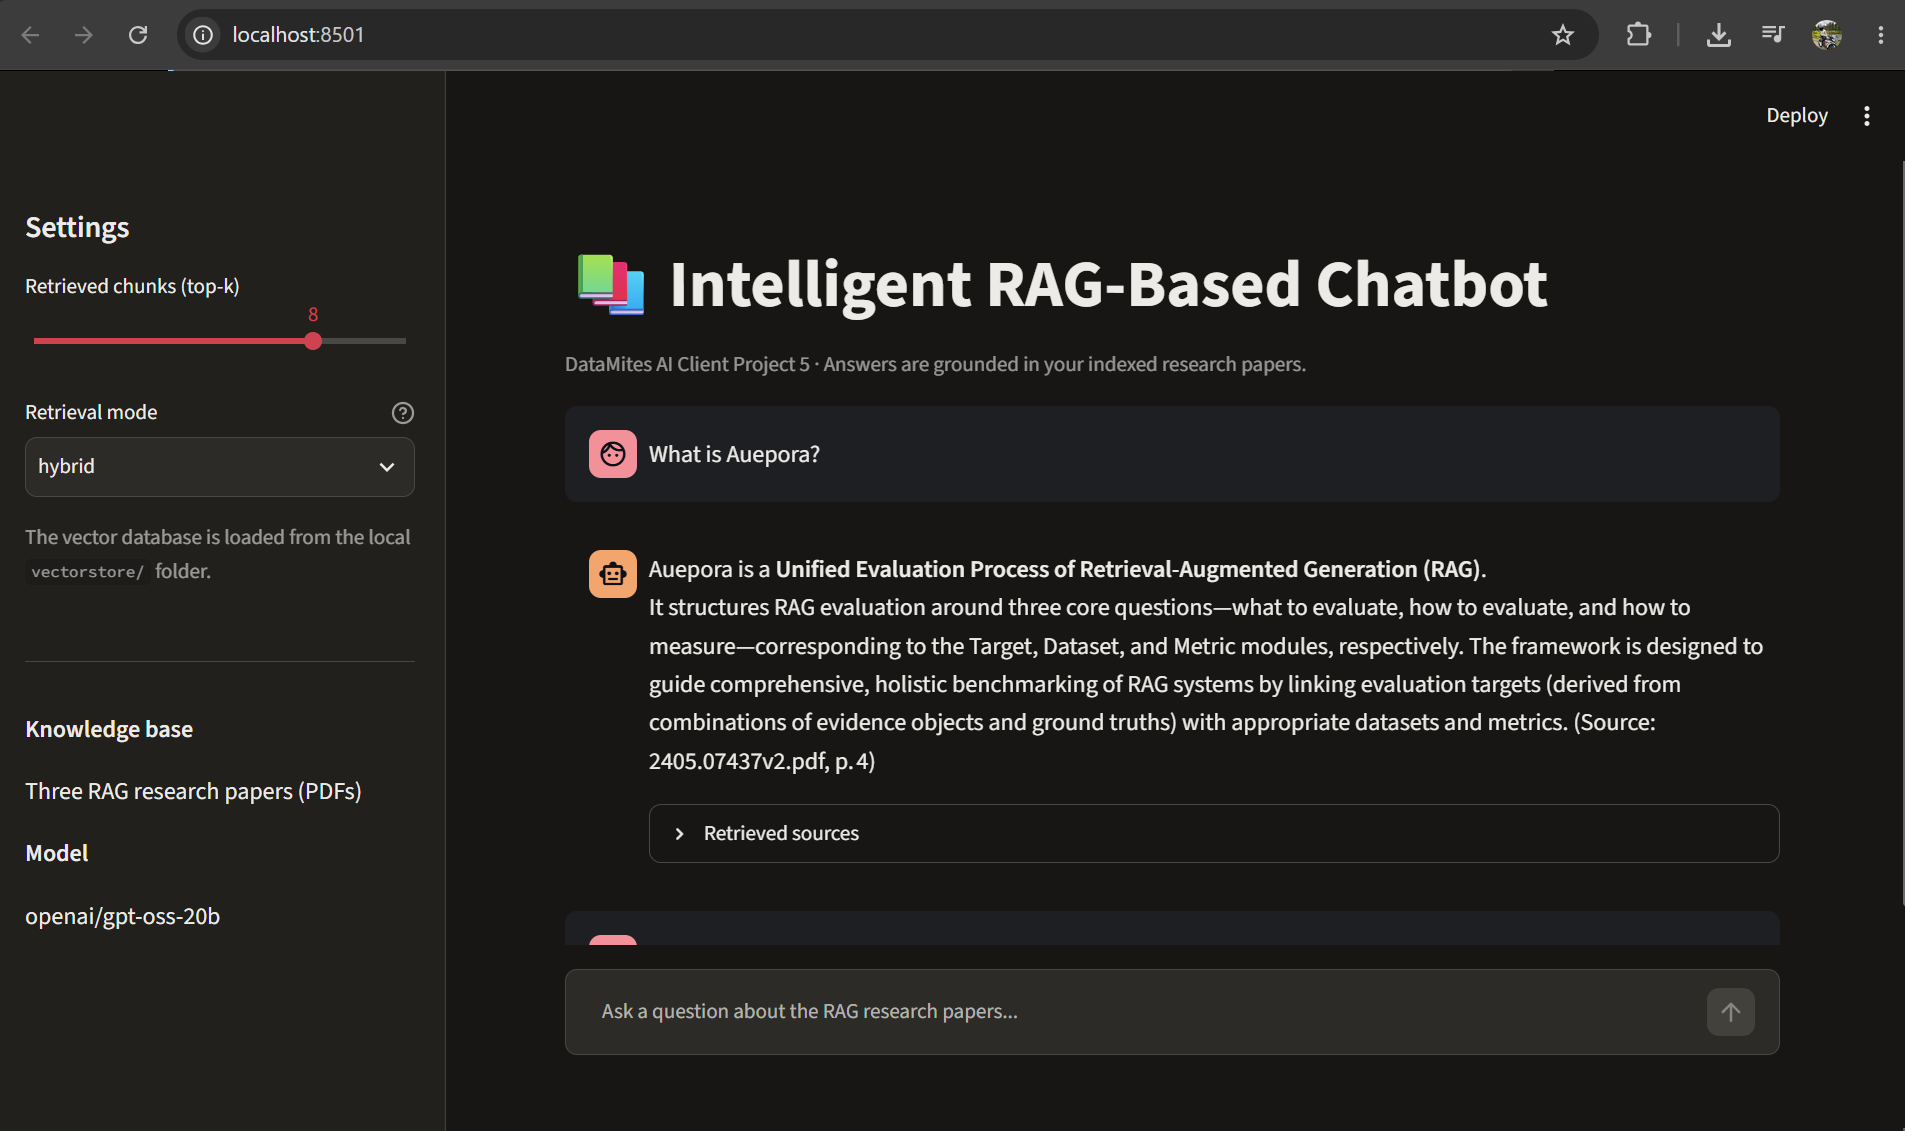

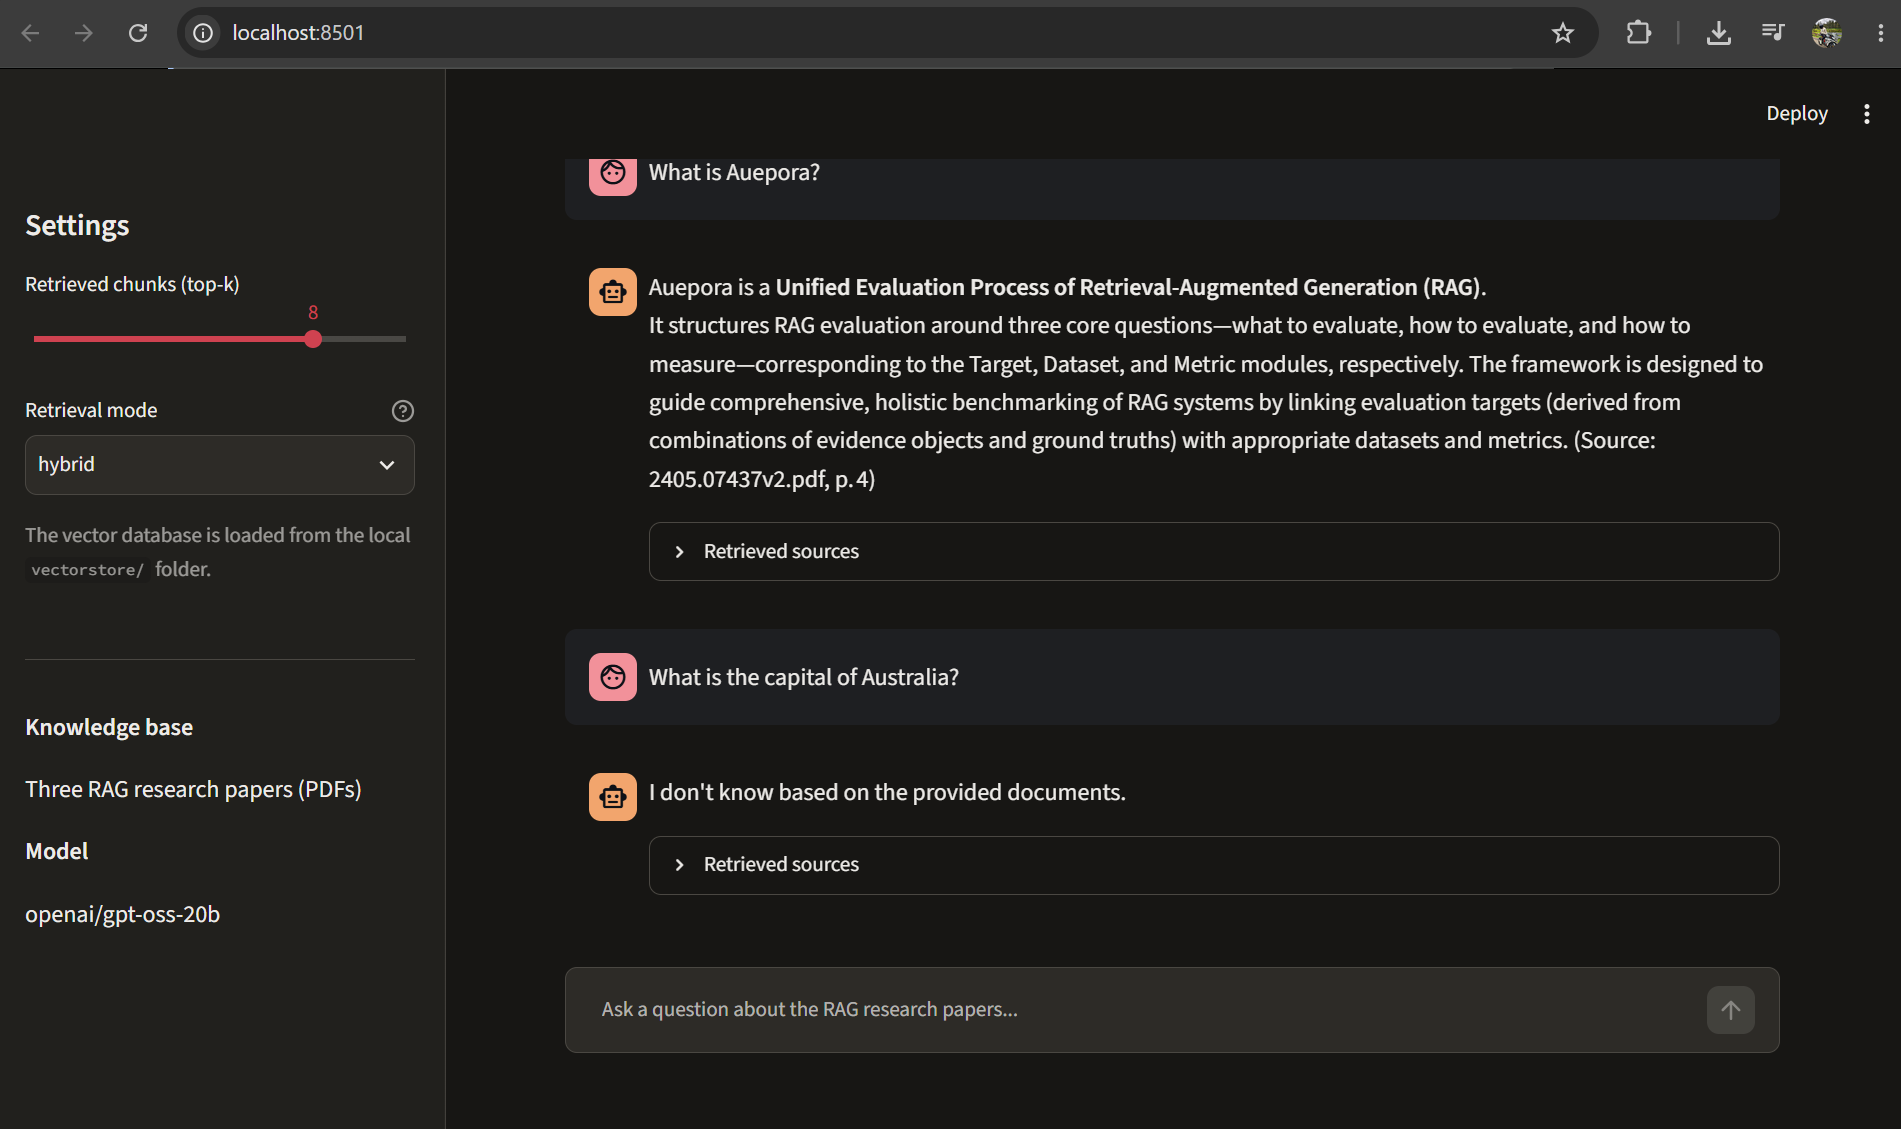


## 17. Save Vector Store and Result Files

This local Jupyter cell creates `rag_artifacts.zip` containing the ChromaDB index (`vectorstore/`) and generated evaluation files (`results/`). The ZIP is saved next to this notebook and shown as a clickable download link.


In [19]:
import importlib.metadata as md
from IPython.display import FileLink, display

PKGS = [
    "langchain-community", "langchain-text-splitters", "langchain-chroma",
    "langchain-huggingface", "langchain-groq", "chromadb",
    "sentence-transformers", "pypdf", "ragas", "datasets", "rank-bm25", "streamlit"
]
pinned = []
for pkg in PKGS:
    try:
        pinned.append(f"{pkg}=={md.version(pkg)}")
    except md.PackageNotFoundError:
        pinned.append(pkg)

(RESULTS_DIR / "requirements_pinned.txt").write_text(
    "\n".join(pinned) + "\n", encoding="utf-8"
)
(RESULTS_DIR / "environment.txt").write_text(
    "Python " + sys.version.split()[0] + "\n"
    "Embedding model: sentence-transformers/all-MiniLM-L6-v2\n"
    f"Answer LLM: Groq {ANSWER_MODEL} (temperature 0)\n"
    f"Judge LLM: Groq {JUDGE_MODEL}\n"
    "Chunking: RecursiveCharacterTextSplitter, 1500 characters, 150 overlap\n"
    f"Retrieval: {RETRIEVAL_MODE} (vector + BM25 keyword, reciprocal rank fusion), top-k = {TOP_K}\n",
    encoding="utf-8"
)
manifest.to_csv(RESULTS_DIR / "chunk_manifest.csv", index=False)

if not VECTOR_DIR.exists():
    raise FileNotFoundError("ChromaDB vectorstore was not found. Run the embeddings/indexing cell first.")

artifact_dir = PROJECT_DIR / "artifacts"
shutil.rmtree(artifact_dir, ignore_errors=True)
artifact_dir.mkdir(parents=True, exist_ok=True)
shutil.copytree(VECTOR_DIR, artifact_dir / "vectorstore")
shutil.copytree(RESULTS_DIR, artifact_dir / "results", dirs_exist_ok=True)

archive = shutil.make_archive(str(PROJECT_DIR / "rag_artifacts"), "zip", root_dir=artifact_dir)
print("Created:", archive)
display(FileLink(archive))
print("Pinned package versions saved to:", RESULTS_DIR / "requirements_pinned.txt")

Created: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\rag_artifacts.zip


C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\rag_artifacts.zip

Pinned package versions saved to: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\results\requirements_pinned.txt


## 18. Design Choices and Evaluation Notes

### Design Choices

- **Chunking (1500 characters, 150 overlap):** large enough to keep a definition and its explanation together, small enough to keep retrieval specific. Section 13 tests 500, 1000 and 1500 with the selection rule stated there.
- **Retrieval (top-k = 8):** gives the model several candidate passages without flooding the prompt. Section 13 compares k = 2, 4, 6 and 8.
- **Embeddings (all-MiniLM-L6-v2):** small, free, can run locally on a CPU, and is a standard sentence-transformers baseline.
- **LLM (Groq `openai/gpt-oss-20b`, temperature 0):** free tier, fast, and deterministic as far as the API allows. The prompt restricts answers to the retrieved context and defines the abstention sentence.

### Reliability Measures

- **Hybrid retrieval** (vector + BM25, reciprocal rank fusion) because specific method names and numbers are matched better by keywords than by embeddings alone.
- **Empty model replies** are retried and are never saved as results. A record only counts as complete when it has a non-empty answer.
- **Checkpoints carry a signature** of the questions, models, retrieval settings and documents. If any of these change, old checkpoints are ignored instead of silently reused.
- **RAGAS is resumable.** Scores are saved per question, so a Groq rate or daily-token limit costs nothing already finished. Partial results are reported as INCOMPLETE, never as final.
- **Groq quota:** free-plan limits are per model and include a daily token cap. A full run (QA generation plus RAGAS) can use a large share of it, so avoid repeating full runs on the same day.

### Evaluation Notes

- The RAGAS evaluation uses 10 question/reference pairs written for the three arXiv papers in `data/`. Replace these pairs when the knowledge base changes.
- RAGAS scores vary from run to run because an LLM acts as the judge, so treat them as indicative. Judge and answer model are configured separately (`JUDGE_MODEL`, `ANSWER_MODEL`); if they fall back to the same model, the same-family bias can push scores upwards.
- The evaluation cell prints how many questions were scored per metric and stops safely when the judge cannot score; re-run it later to resume.
- Evaluation scores are generated from an actual RAGAS run. Do not edit or fabricate scores to meet targets; investigate retrieval, context quality, prompts and failed judge jobs, then rerun the evaluation.

### Constraints and Usage Notes

- Equations, tables and figures in the papers are not extracted reliably, and there is no OCR. The two surveys overlap in places (for example evaluation metrics), so related passages can come from either paper.
- Retrieval can still miss passages. Section 13 measures vector, keyword and hybrid retrieval with a hit-rate table for chunk size and k, and the per-question CSV shows which questions were missed.
- The chat loop is single-turn and does not keep conversation memory.
- This notebook is adapted for local Anaconda Jupyter. It does not import `google.colab` or use `/content/` paths.
- Keep the `data/` folder beside this notebook. The notebook expects PDF, TXT, or Markdown files there.
- The Streamlit UI (`app.py`, written by Section 16) reads the persisted ChromaDB index.
- Keep API keys out of source code and version control. The notebook asks for the Groq key using `getpass`; Streamlit can read it from an environment variable or `.streamlit/secrets.toml`.


## 19. Test Results and Known Limitations

### Test Table (Recorded Run)

| # | Test | Query type | Expected behaviour | Actual behaviour | Result |
|---|---|---|---|---|---|
| 1 | RAGAS reference set, 10 questions | Factual, three papers | Grounded, cited answers | 9 of 10 answered; faithfulness 0.883, answer relevancy 0.813 (targets 0.85 / 0.80) | Pass |
| 2 | "What four abilities are used to evaluate RAG models?" | Factual, evaluation survey | Answer naming the four abilities | Retrieval missed the key passage, so the bot abstained; scored 0 on both metrics | **Fail (documented)** |
| 3 | Four out-of-scope questions (cricket, capital city, recipe, Bitcoin) | Unsupported | Standard "I don't know" sentence | 4 of 4 abstained | Pass |
| 4 | Retrieval comparison at chunk size 1500, k = 8 | Retrieval quality | Hybrid not worse than single methods | Hit rate: vector 0.4, keyword 0.9, hybrid 0.9 | Pass |
| 5 | Streamlit: "What is Auepora?" (hybrid, k = 8) | Factual | Cited answer plus sources panel | Answer cited 2405.07437v2.pdf, p. 4, with retrieved sources | Pass |
| 6 | Streamlit: "What is the capital of Australia?" | Unsupported | Abstain | "I don't know based on the provided documents." | Pass |
| 7 | Streamlit with an invalid Groq key | Failure case | Readable error, no crash | Chat showed "Request failed: Error code: 401 - Invalid API Key" | Pass (observed during testing) |
| 8 | Groq daily token limit reached during QA generation | Failure case | Stop safely and keep progress | Cell stopped with a clear message and resumed from the checkpoint | Pass (observed during testing) |
| 9 | Missing key, missing `vectorstore/`, empty collection | Configuration errors | Clear message, app stops | Handled in `app.py` with `st.error` and `st.stop` | Code-verified only, not triggered live |

Empty submissions are not sent by Streamlit's chat input; this was not tested separately.

### Known Limitations

- **Duplicate content:** a chunk returned by both vector and BM25 search is merged into one entry by Reciprocal Rank Fusion (same chunk key). Near-duplicate text that appears in different papers is not removed and can occupy several of the top-k slots.
- **Conflicting sources:** the system does not decide between conflicting statements. The prompt restricts answers to the retrieved context, and every answer shows its source file and page so the reader can compare.
- **Document updates:** the vector store is tied to a fingerprint of the corpus. When files in `data/` change, the index is rebuilt; there is no incremental update.
- **Scanned PDFs and OCR:** only selectable text is extracted. Scanned pages, images, equations and complex tables are not read reliably, and no OCR step is included.
- **Retrieval misses:** one of ten evaluation questions was missed (test 2). Hit rate is 0.90 at the default setting, measured on a small 10-question set.
- **Evaluation variance:** RAGAS depends on the judge model and can change between runs; the scores come from one recorded run.
- **Security:** the index uses ChromaDB and does not load pickled files. The API key is entered through a hidden prompt or an environment variable and is never saved in the notebook.


## 20. Client Requirement Audit

The following checklist maps the submitted client brief to the implementation in this notebook.

| Client brief requirement | Where it is implemented | Status / note |
|---|---|---|
| Build a domain-specific RAG chatbot | Sections 1–10; three RAG research-paper PDFs | **Covered** |
| Choose a knowledge source (PDF, website, CSV, or custom) | Section 6 downloads three arXiv PDFs into `data/` | **Covered — PDF option** |
| LangChain orchestration | PDF loaders, text splitter, prompt, Chroma integration | **Covered** |
| Select one LLM backend | Groq ChatGroq; answer and judge models configured separately | **Covered — Groq** |
| Select a vector store | Persistent ChromaDB collection | **Covered** |
| Select an embedding model | Hugging Face `sentence-transformers/all-MiniLM-L6-v2` | **Covered** |
| Document ingestion | Section 7 loads PDF, TXT and Markdown files | **Covered** |
| Chunking with overlap | Section 7 uses 1,500-character chunks and 150-character overlap; Section 13 compares sizes | **Covered** |
| Embedding generation | Section 9 | **Covered** |
| Vector indexing | Section 9 persists ChromaDB under `vectorstore/` | **Covered** |
| Query processing and top-k retrieval | Section 10; top-k defaults to 8 | **Covered** |
| Augmented prompt and grounded answer | `rag_core.py` prompt restricts answers to retrieved context | **Covered** |
| User interface | Section 15 provides CLI; Section 16 generates Streamlit `app.py` | **Covered** |
| Test table, failure cases and limitations | Section 19 | **Covered** |
| 10 sample Q&A pairs | Section 12 defines the 10 reference pairs and generates and checks the 10 answers | **Covered** |
| Faithfulness and relevancy evaluation with RAGAS | Section 12 evaluation uses Faithfulness and ResponseRelevancy | **Covered** |
| Evaluation results | Section 14 calculates and saves scores; recorded run shows 10/10 scores | **Covered** (recorded run: faithfulness 0.883, answer relevancy 0.813) |
| One-page problem-domain description | The Problem Statement section at the top of the notebook describes the RAG research-paper Q&A use case and knowledge base | **Covered** |
| Architecture diagram | The System Architecture section near the top contains the architecture diagram image | **Covered** |
| README with setup, architecture and run instructions | Section 21 below creates `README.md` when executed | **Covered** (Section 21 writes `README.md`) |
| Reproducible vector store | Section 9 rebuilds/reuses the index based on a corpus fingerprint; Section 17 packages it | **Covered** (corpus fingerprint, Section 9) |
| Save project artifacts | Section 17 creates `rag_artifacts.zip` with vectorstore and results | **Covered** (Section 17) |

### Notes on Scope

- The brief says to choose **one** knowledge-base option. This project chooses the **PDF/document Q&A** option; website scraping and CSV ingestion are not required for this chosen option.
- The brief lists several alternative LLMs, vector stores and embedding models. This implementation selects Groq, ChromaDB and Sentence Transformers; it does not need to implement every alternative.
- The RAGAS scores shown in the saved notebook outputs are from a previous successful run. They are not a promise that a fresh run will produce identical values.
- The notebook creates the vector database, helper module, Streamlit app, README and ZIP only when the relevant cells are executed in order. Keep `data/`, `rag_core.py`, `app.py`, `vectorstore/` and `results/` together in the project folder.


## 21. Generate Project README

Run the next cell to create `README.md` in the same folder as this notebook. It documents installation, architecture, execution, evaluation and generated artifacts.


In [27]:
from pathlib import Path

readme_text = r"""# Intelligent RAG-Based Chatbot

DataMites AI Engineering Track — Client Project 5

## Problem domain

This project provides question answering over a focused knowledge base of three arXiv research papers about Retrieval-Augmented Generation (RAG). The use case is to help a learner ask questions about RAG methods, architecture and evaluation while receiving answers grounded in retrieved passages rather than unsupported general model knowledge.

## Technology stack

- Python and Jupyter Notebook
- LangChain for document loading, splitting and LLM orchestration
- Hugging Face `sentence-transformers/all-MiniLM-L6-v2` for embeddings
- ChromaDB for persistent vector storage
- BM25 keyword retrieval combined with vector retrieval using Reciprocal Rank Fusion
- Groq API for answer generation
- RAGAS for Faithfulness and Answer Relevancy evaluation
- Streamlit for the web interface

## Architecture

```text
PDF/TXT/Markdown documents
          |
    LangChain loaders
          |
  Cleaning and chunking
          |
 Sentence Transformer embeddings
          |
   +------+------+
   |             |
 ChromaDB       BM25
 vector        keyword
 search        search
   |             |
   +------+------+
          |
 Reciprocal Rank Fusion
          |
 Retrieved context + question
          |
 Grounded prompt -> Groq LLM
          |
 Answer + source/page labels
          |
     CLI / Streamlit

10 reference Q&A pairs -> RAGAS -> Faithfulness + Answer Relevancy
```

## Setup

1. Install Python and Anaconda, then open this notebook in Jupyter.
2. Run the notebook cells from top to bottom. The installation cell installs the required packages.
3. The data cell downloads the three selected arXiv PDFs into `data/` when they are not already present. You can also place your own PDF, TXT or Markdown files in that folder.
4. When prompted, enter a Groq API key. The key is requested through hidden input and is not written into the notebook.
5. Continue through document loading, chunking, embedding and ChromaDB indexing.

## Run the chatbot

After the notebook has created `vectorstore/`, `rag_core.py` and `app.py`, open a terminal in the same project directory and set your API key.

Windows Command Prompt:

```bat
set GROQ_API_KEY=your_groq_key
python -m streamlit run app.py
```

Windows PowerShell:

```powershell
$env:GROQ_API_KEY="your_groq_key"
python -m streamlit run app.py
```

Open the local Streamlit URL printed in the terminal (normally `http://localhost:8501`). The app provides retrieval-mode and top-k controls and displays retrieved source/page labels.

For an interactive notebook command-line chat, call `chat_cli()` after the RAG pipeline has been initialized.

## Evaluation

The notebook contains ten reference Q&A pairs and evaluates generated answers using RAGAS Faithfulness and Answer Relevancy. It also tests out-of-scope questions and compares vector, keyword and hybrid retrieval settings. Scores are saved under `results/`. RAGAS values depend on the LLM judge and may vary between runs; report only completed scores.

## Generated files

- `data/` — source documents
- `rag_core.py` — shared retrieval and answer-generation functions
- `vectorstore/` — persistent ChromaDB index
- `app.py` — Streamlit application
- `results/` — QA, RAGAS, retrieval and environment reports
- `rag_artifacts.zip` — packaged vector store and results (created by the final packaging cell)

## Notes

Keep the notebook and generated project files in the same directory. Do not commit or share your Groq API key. The PDF loader extracts selectable text; scanned pages, complex tables, equations and figures may not be represented accurately. The chatbot is document-grounded and is not a general web-search system.
"""

Path("README.md").write_text(readme_text, encoding="utf-8")
print("Created:", Path("README.md").resolve())
print("README characters:", len(readme_text))


Created: C:\Users\sarav\Data Mites\AI\Intenship Projects\AI Clients\README.md
README characters: 3737
